<a href="https://colab.research.google.com/github/Duman18/portfolio-risk-engine/blob/main/03_backtest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

url = "https://raw.githubusercontent.com/Duman18/portfolio-risk-engine/refs/heads/main/returns.csv"
returns = pd.read_csv(url, index_col=0, parse_dates=True)

weights = np.array([0.2, 0.2, 0.2, 0.2, 0.2])
port_returns = returns.dot(weights)

V = 1_000_000
mu = port_returns.mean()
sigma = port_returns.std()

In [3]:
rows = []
for cl in [0.95, 0.99]:
    alpha = 1 - cl
    q = np.percentile(port_returns, alpha * 100)

    hist_var = -q * V
    hist_es  = -port_returns[port_returns <= q].mean() * V
    param_es = -(mu - sigma * norm.pdf(norm.ppf(alpha)) / alpha) * V

    rows.append([f"{int(cl*100)}%", hist_var, hist_es, param_es])

es_table = pd.DataFrame(rows, columns=["Confidence", "Historical VaR", "Historical ES", "Parametric ES"])
es_table = es_table.set_index("Confidence").round(0)
es_table

,Historical VaR,Historical ES,Parametric ES
Confidence,,,
95%,21586.0,31300.0,29335.0
99%,35116.0,49135.0,38065.0


In [4]:
window = 250
a = 0.05

roll = port_returns.rolling(window)

hist_var_r  = -roll.quantile(a).shift(1)
param_var_r = -(roll.mean() + norm.ppf(a) * roll.std()).shift(1)

bt = pd.DataFrame({
    "actual":    port_returns,
    "hist_var":  hist_var_r,
    "param_var": param_var_r
}).dropna()

bt.head()

,actual,hist_var,param_var
Date,,,
2016-01-08,0.008298,0.020017,0.024561
2016-01-11,-0.027254,0.020017,0.024537
2016-01-12,-0.008376,0.020957,0.024813
2016-01-13,0.012333,0.020957,0.024881
2016-01-14,-0.006407,0.020957,0.024883


In [5]:
bt["hist_breach"]  = bt["actual"] < -bt["hist_var"]
bt["param_breach"] = bt["actual"] < -bt["param_var"]

n = len(bt)
print("Days tested:", n)
print("Expected breach rate:", a * 100, "%")
print("Historical breaches:", bt["hist_breach"].sum(),
      "→", round(bt["hist_breach"].mean() * 100, 2), "%")
print("Parametric breaches:", bt["param_breach"].sum(),
      "→", round(bt["param_breach"].mean() * 100, 2), "%")

Days tested: 2457
Expected breach rate: 5.0 %
Historical breaches: 132 → 5.37 %
Parametric breaches: 113 → 4.6 %


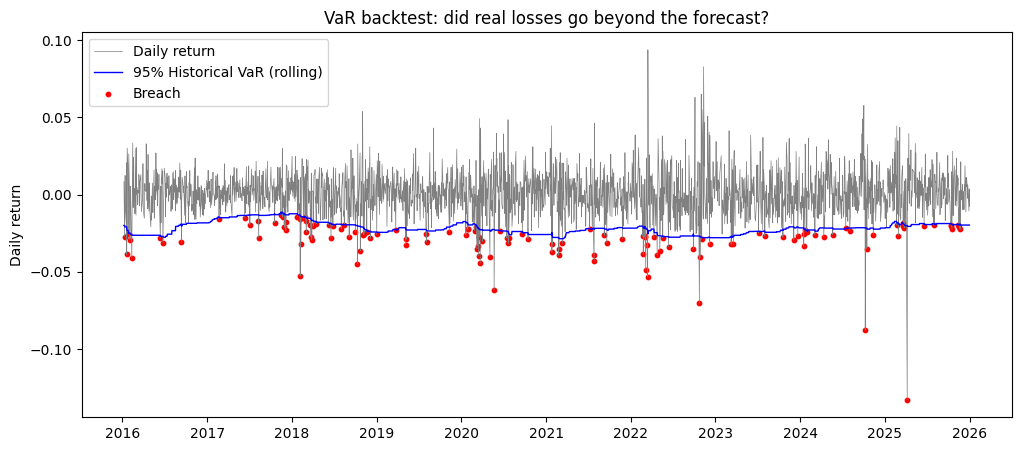

In [6]:
plt.figure(figsize=(12,5))
plt.plot(bt.index, bt["actual"], color="grey", linewidth=0.5, label="Daily return")
plt.plot(bt.index, -bt["hist_var"], color="blue", linewidth=1, label="95% Historical VaR (rolling)")

br = bt[bt["hist_breach"]]
plt.scatter(br.index, br["actual"], color="red", s=10, label="Breach")

plt.title("VaR backtest: did real losses go beyond the forecast?")
plt.ylabel("Daily return")
plt.legend()
plt.savefig("backtest_chart.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
by_year = bt.groupby(bt.index.year)[["hist_breach", "param_breach"]].mean() * 100
by_year.round(1)

,hist_breach,param_breach
Date,,
2016,3.3,2.9
2017,4.5,4.5
2018,10.6,10.2
2019,2.8,3.7
2020,7.7,8.1
2021,4.5,4.5
2022,6.9,6.1
2023,2.9,1.2
2024,4.9,4.1


In [8]:
from scipy.stats import binomtest

results = []
for a_level in [0.05, 0.01]:
    hv = -roll.quantile(a_level).shift(1)
    pv = -(roll.mean() + norm.ppf(a_level) * roll.std()).shift(1)
    tmp = pd.DataFrame({"actual": port_returns, "hv": hv, "pv": pv}).dropna()

    hb = (tmp["actual"] < -tmp["hv"])
    pb = (tmp["actual"] < -tmp["pv"])
    n_days = len(tmp)

    results.append([
        f"{int((1-a_level)*100)}% VaR",
        f"{a_level*100:.0f}%",
        f"{hb.mean()*100:.2f}%",
        f"{pb.mean()*100:.2f}%",
        round(binomtest(int(hb.sum()), n_days, a_level).pvalue, 3),
        round(binomtest(int(pb.sum()), n_days, a_level).pvalue, 3),
    ])

summary = pd.DataFrame(results, columns=[
    "Level", "Expected", "Historical breaches", "Parametric breaches",
    "Historical p-value", "Parametric p-value"]).set_index("Level")
summary

,Expected,Historical breaches,Parametric breaches,Historical p-value,Parametric p-value
Level,,,,,
95% VaR,5%,5.37%,4.60%,0.404,0.379
99% VaR,1%,1.22%,1.55%,0.264,0.011


## Results

### Expected Shortfall
At 95%, ES is HK$____ compared with VaR of HK$____. On the worst 5% of days, the average loss is about __% larger than VaR suggests.

### Backtest (2016–2025, 250-day rolling window)

| Level | Expected | Historical | Parametric |
|---|---|---|---|
| 95% VaR | 5% | 5.37% (p = 0.40) ✅ | 4.60% (p = 0.38) ✅ |
| 99% VaR | 1% | 1.22% (p = 0.26) ✅ | 1.55% (p = 0.01) ❌ |

A p-value below 0.05 means the breach rate is too far from the target to be explained by chance, so the model fails the test.

### Breaches by year (95% VaR)
Breaches cluster in crisis years: **2018 (10.6%)**, **2020 (7.7%)** and **2022 (6.9%)**, while calm years such as 2016, 2019 and 2023 stay below 3.5%.

### Key findings
1. **Historical VaR passes all tests; parametric VaR fails at 99%.** The normal-distribution model is breached 1.55% of the time instead of 1% (p = 0.011), confirming that it underestimates extreme losses (fat tails).
2. **VaR reacts too slowly.** Because it uses the past 250 days, the model underestimates risk at the start of a crisis and only adjusts after large losses have already happened.
3. **Sensitivity to single shocks.** In 2025, one extreme day increased the estimated volatility, so parametric VaR became overly cautious (0.8% breaches vs 5% expected), while historical VaR stayed close to target (5.7%).